In [2]:
import pandas as pd

# Path to the training CSV
train_csv_path = "/kaggle/input/datasets/priyankabapujadhav/traffic-data/Train_csv/Train.csv"

# Load the CSV
train_df = pd.read_csv(train_csv_path)

# Show first few rows
train_df.head()

,Width,Height,Roi.X1,Roi.Y1,Roi.X2,Roi.Y2,ClassId,Path
0,27,26,5,5,22,20,20,Train/20/00020_00000_00000.png
1,28,27,5,6,23,22,20,Train/20/00020_00000_00001.png
2,29,26,6,5,24,21,20,Train/20/00020_00000_00002.png
3,28,27,5,6,23,22,20,Train/20/00020_00000_00003.png
4,28,26,5,5,23,21,20,Train/20/00020_00000_00004.png


In [3]:
import torch
torch.cuda.is_available()

True

In [4]:
import os

BASE_PATH = "/kaggle/input/datasets/priyankabapujadhav/traffic-data/Train"

# Example check
image_path = os.path.join(BASE_PATH, "Train/38/00038_00037_00013.png")
print("Example image exists:", os.path.exists(image_path))

# Check first 10 CSV paths
print("\nChecking first 10 paths from CSV:\n")

for path in train_df['Path'].head(10):
    full_path = os.path.join(BASE_PATH, path)
    print(full_path, "Exists:", os.path.exists(full_path))

Example image exists: True

Checking first 10 paths from CSV:

/kaggle/input/datasets/priyankabapujadhav/traffic-data/Train/Train/20/00020_00000_00000.png Exists: True
/kaggle/input/datasets/priyankabapujadhav/traffic-data/Train/Train/20/00020_00000_00001.png Exists: True
/kaggle/input/datasets/priyankabapujadhav/traffic-data/Train/Train/20/00020_00000_00002.png Exists: True
/kaggle/input/datasets/priyankabapujadhav/traffic-data/Train/Train/20/00020_00000_00003.png Exists: True
/kaggle/input/datasets/priyankabapujadhav/traffic-data/Train/Train/20/00020_00000_00004.png Exists: True
/kaggle/input/datasets/priyankabapujadhav/traffic-data/Train/Train/20/00020_00000_00005.png Exists: True
/kaggle/input/datasets/priyankabapujadhav/traffic-data/Train/Train/20/00020_00000_00006.png Exists: True
/kaggle/input/datasets/priyankabapujadhav/traffic-data/Train/Train/20/00020_00000_00007.png Exists: True
/kaggle/input/datasets/priyankabapujadhav/traffic-data/Train/Train/20/00020_00000_00008.png Exist

In [5]:
import os

BASE_PATH = "/kaggle/input/datasets/priyankabapujadhav/traffic-data/Train"

# Image to check
image_rel_path = "Train/38/00038_00037_00013.png"
image_path = os.path.join(BASE_PATH, image_rel_path)

print("Checking:", image_path)
print("Exists:", os.path.exists(image_path))

if os.path.exists(image_path):
    print("File size:", os.path.getsize(image_path), "bytes")
else:
    print("File NOT found ❌")

Checking: /kaggle/input/datasets/priyankabapujadhav/traffic-data/Train/Train/38/00038_00037_00013.png
Exists: True
File size: 3657 bytes


In [6]:
import os
import numpy as np
import tensorflow as tf
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout, Input
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.utils.class_weight import compute_class_weight

2026-02-21 23:20:57.442834: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1771716057.845617      55 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1771716057.956646      55 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1771716058.850457      55 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1771716058.850502      55 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1771716058.850505      55 computation_placer.cc:177] computation placer alr

In [7]:
# ======================
# Paths
# ======================

dataset_path = "/kaggle/input/datasets/priyankabapujadhav/traffic-data/Train"
train_dir = os.path.join(dataset_path, 'Train')

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

# ======================
# Data Augmentation
# ======================

datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=30,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    validation_split=0.2
)

train_data = datagen.flow_from_directory(
    train_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='training'
)

val_data = datagen.flow_from_directory(
    train_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='validation'
)

Found 31368 images belonging to 43 classes.
Found 7841 images belonging to 43 classes.


In [8]:
# ======================
# Class Weights
# ======================

class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(train_data.classes),
    y=train_data.classes
)

class_weights = dict(enumerate(class_weights))

print("Class weights computed ✅")

Class weights computed ✅


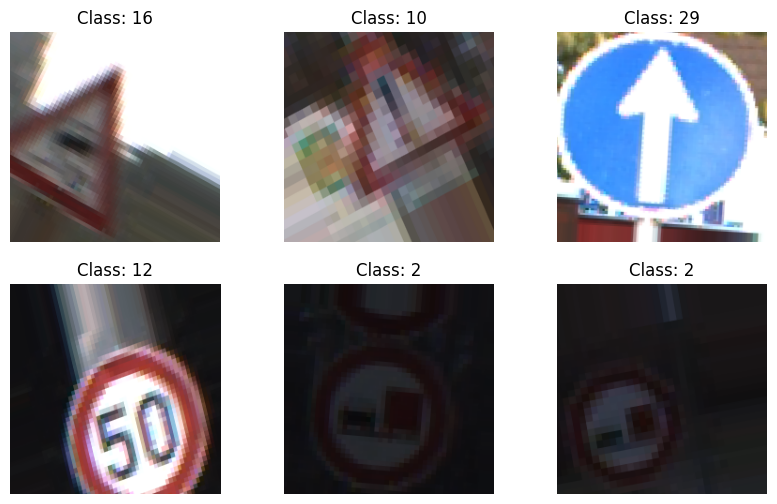

In [9]:
import matplotlib.pyplot as plt
import numpy as np

images, labels = next(train_data)

plt.figure(figsize=(10,6))
for i in range(6):
    plt.subplot(2,3,i+1)
    plt.imshow(images[i])
    plt.title(f"Class: {np.argmax(labels[i])}")
    plt.axis('off')

plt.show()

In [10]:
# ======================
# Model Building (SAFE)
# ======================

base_model = EfficientNetB0(
    weights='imagenet',
    include_top=False,
    input_shape=(224, 224, 3)
)


I0000 00:00:1771716138.243314      55 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13757 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1771716138.249315      55 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13757 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [11]:
# Fine tuning strategy (same as your working code)
base_model.trainable = True

for layer in base_model.layers[:100]:
    layer.trainable = False

# Functional API (deployment safe)
inputs = Input(shape=(224, 224, 3))

x = base_model(inputs, training=False)
x = GlobalAveragePooling2D()(x)
x = Dense(512, activation='relu')(x)
x = Dropout(0.5)(x)
outputs = Dense(train_data.num_classes, activation='softmax')(x)

model = Model(inputs, outputs)

In [ ]:
os.makedirs("/kaggle/working/best_model", exist_ok=True)

os.makedirs("/kaggle/working/traffic_model", exist_ok=True)

print("directory is created")

In [12]:
# ======================
# Compile
# ======================

model.compile(
    optimizer=Adam(learning_rate=1e-4),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print("Model compiled successfully ✅")

Model compiled successfully ✅


In [13]:
# ======================
# Callbacks
# ======================

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=3,
    verbose=1
)

checkpoint = ModelCheckpoint(
    'efficientnet_best_model.keras',
    monitor='val_accuracy',
    save_best_only=True,
    verbose=1
)

callbacks = [early_stopping, reduce_lr, checkpoint]

In [14]:
# ======================
# Training
# ======================

history = model.fit(
    train_data,
    validation_data=val_data,
    epochs=20,
    class_weight=class_weights,
    callbacks=callbacks
)


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/20


I0000 00:00:1771716185.421483     157 service.cc:152] XLA service 0x7f9bac002c50 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1771716185.421522     157 service.cc:160]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1771716185.421527     157 service.cc:160]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5
I0000 00:00:1771716190.320690     157 cuda_dnn.cc:529] Loaded cuDNN version 91002
2026-02-21 23:23:19.509432: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-02-21 23:23:19.653692: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-02-21 23:23:19.993900: E external/local_xl

465/981 ━━━━━━━━━━━━━━━━━━━━ 4:43 549ms/step - accuracy: 0.0352 - loss: 3.7517

2026-02-21 23:28:04.400750: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-02-21 23:28:04.537197: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-02-21 23:28:04.857939: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-02-21 23:28:05.000085: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-02-21 23:28:05.739583: E external/local_xla/xla/stream_

981/981 ━━━━━━━━━━━━━━━━━━━━ 0s 600ms/step - accuracy: 0.0507 - loss: 3.6108

2026-02-21 23:36:09.229919: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-02-21 23:36:09.366376: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-02-21 23:36:10.100670: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-02-21 23:36:10.236686: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.



Epoch 1: val_accuracy improved from -inf to 0.15228, saving model to efficientnet_best_model.keras
981/981 ━━━━━━━━━━━━━━━━━━━━ 815s 771ms/step - accuracy: 0.0508 - loss: 3.6105 - val_accuracy: 0.1523 - val_loss: 3.1119 - learning_rate: 1.0000e-04
Epoch 2/20
981/981 ━━━━━━━━━━━━━━━━━━━━ 0s 440ms/step - accuracy: 0.2888 - loss: 2.4028
Epoch 2: val_accuracy improved from 0.15228 to 0.36539, saving model to efficientnet_best_model.keras
981/981 ━━━━━━━━━━━━━━━━━━━━ 537s 548ms/step - accuracy: 0.2889 - loss: 2.4024 - val_accuracy: 0.3654 - val_loss: 2.2313 - learning_rate: 1.0000e-04
Epoch 3/20
981/981 ━━━━━━━━━━━━━━━━━━━━ 0s 431ms/step - accuracy: 0.5599 - loss: 1.3231
Epoch 3: val_accuracy improved from 0.36539 to 0.59801, saving model to efficientnet_best_model.keras
981/981 ━━━━━━━━━━━━━━━━━━━━ 529s 539ms/step - accuracy: 0.5599 - loss: 1.3229 - val_accuracy: 0.5980 - val_loss: 1.2980 - learning_rate: 1.0000e-04
Epoch 4/20
981/981 ━━━━━━━━━━━━━━━━━━━━ 0s 431ms/step - accuracy: 0.7210 

In [15]:
os.makedirs("/kaggle/working/best_model", exist_ok=True)

os.makedirs("/kaggle/working/traffic_model", exist_ok=True)

print("directory is created")

directory is created


In [16]:
model.save("/kaggle/working/traffic_model/efficientnet_final_model.keras")
model.save("/kaggle/working/traffic_model/efficientnet_final_model.h5")

print("Model trained and saved successfully ✅")

Model trained and saved successfully ✅


In [2]:
import os
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.utils.class_weight import compute_class_weight



test_dir = "/kaggle/input/datasets/priyankabapujadhav/evaluate-data/Organized_Test"

# Image size and batch size
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=30,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    validation_split=0.2
)


# Load best model
model = tf.keras.models.load_model(
    "/kaggle/input/datasets/priyankabapujadhav/best-model/efficientnet_best_model.keras"
)

# Evaluate on test data
test_data = datagen.flow_from_directory(
    test_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

test_loss, test_acc = model.evaluate(test_data)
print(f"Test Accuracy: {test_acc:.2f}")
print(f"Test Loss: {test_loss:.2f}")


2026-02-24 14:23:59.537975: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1771943039.762359      55 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1771943039.823541      55 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1771943040.363457      55 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1771943040.363497      55 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1771943040.363500      55 computation_placer.cc:177] computation placer alr

Found 12630 images belonging to 43 classes.


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()
I0000 00:00:1771943079.841375     126 service.cc:152] XLA service 0x7db9a4012560 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1771943079.841414     126 service.cc:160]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1771943079.841419     126 service.cc:160]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5
I0000 00:00:1771943080.805066     126 cuda_dnn.cc:529] Loaded cuDNN version 91002
2026-02-24 14:24:47.276109: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal

394/395 ━━━━━━━━━━━━━━━━━━━━ 0s 432ms/step - accuracy: 0.9205 - loss: 0.3708

2026-02-24 14:27:49.154290: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-02-24 14:27:49.337309: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-02-24 14:27:49.825600: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-02-24 14:27:50.028102: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-02-24 14:27:50.861188: E external/local_xla/xla/stream_

395/395 ━━━━━━━━━━━━━━━━━━━━ 199s 458ms/step - accuracy: 0.9204 - loss: 0.3712
Test Accuracy: 0.90
Test Loss: 0.44


In [14]:
model.save("/kaggle/working/efficientnet_final_evaluate_model.keras")

395/395 ━━━━━━━━━━━━━━━━━━━━ 159s 388ms/step


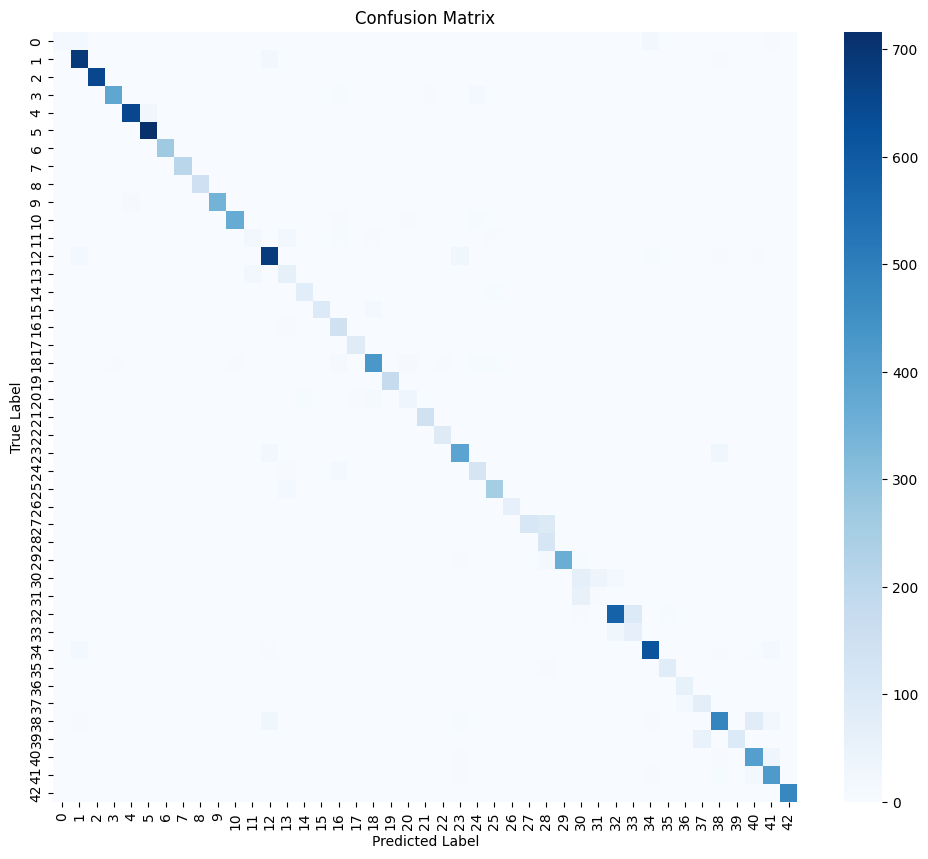

              precision    recall  f1-score   support

           0       1.00      0.32      0.48        60
           1       0.93      0.96      0.94       720
           2       1.00      0.99      0.99       660
           3       0.98      0.91      0.94       420
           4       0.98      0.95      0.96       690
           5       0.96      0.99      0.98       720
           6       0.99      0.99      0.99       270
           7       0.99      0.99      0.99       210
           8       0.99      1.00      0.99       150
           9       0.99      0.96      0.97       360
          10       0.99      0.94      0.97       390
          11       0.43      0.33      0.38        60
          12       0.89      0.91      0.90       750
          13       0.56      0.71      0.62        90
          14       0.89      0.88      0.88        90
          15       0.98      0.83      0.90       120
          16       0.75      0.95      0.84       150
          17       0.95    

In [3]:
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

# Predict on test data
Y_pred = model.predict(test_data)
y_pred = np.argmax(Y_pred, axis=1)

# True labels
y_true = test_data.classes

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)

# Plot Heatmap
plt.figure(figsize=(12,10))
sns.heatmap(cm, annot=False, cmap='Blues')
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

# Classification Report
print(classification_report(y_true, y_pred))

In [6]:
import tensorflow as tf
import matplotlib.pyplot as plt
import os

from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout,BatchNormalization
from tensorflow.keras.models import Model
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.optimizers import Adam

# Paths
train_dir = "/kaggle/input/datasets/priyankabapujadhav/traffic-data/Train/Train"   # change if needed
val_dir = "/kaggle/input/datasets/priyankabapujadhav/traffic-data/Train/Train"     # using validation split

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
EPOCHS = 5

# Data Generator
datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2
)

train_data = datagen.flow_from_directory(
    train_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    subset='training',
    class_mode='categorical'
)

val_data = datagen.flow_from_directory(
    val_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    subset='validation',
    class_mode='categorical'
)

NUM_CLASSES = train_data.num_classes

# Model
base_model = EfficientNetB0(
    weights='imagenet',
    include_top=False,
    input_shape=(224,224,3)
)

base_model.trainable = False

x = base_model.output
x = GlobalAveragePooling2D()(x)
x = BatchNormalization()(x)
x = Dense(256, activation='relu')(x)
x = Dropout(0.5)(x)

output = Dense(NUM_CLASSES, activation='softmax')(x)

model = Model(inputs=base_model.input, outputs=output)

model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Training
history = model.fit(
    train_data,
    validation_data=val_data,
    epochs=EPOCHS
)

# Save model
model.save("/kaggle/working/efficientnet_fast_model.keras")

print("Model Saved!")


Found 31368 images belonging to 43 classes.
Found 7841 images belonging to 43 classes.
Epoch 1/5
981/981 ━━━━━━━━━━━━━━━━━━━━ 0s 123ms/step - accuracy: 0.0479 - loss: 3.8186

2026-02-24 14:38:25.349962: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-02-24 14:38:25.527071: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-02-24 14:38:25.706734: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-02-24 14:38:25.889316: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-02-24 14:38:26.071497: E external/local_xla/xla/stream_

981/981 ━━━━━━━━━━━━━━━━━━━━ 185s 170ms/step - accuracy: 0.0479 - loss: 3.8185 - val_accuracy: 0.0566 - val_loss: 3.6410
Epoch 2/5
981/981 ━━━━━━━━━━━━━━━━━━━━ 65s 67ms/step - accuracy: 0.0577 - loss: 3.5403 - val_accuracy: 0.0566 - val_loss: 3.5483
Epoch 3/5
981/981 ━━━━━━━━━━━━━━━━━━━━ 65s 66ms/step - accuracy: 0.0539 - loss: 3.5242 - val_accuracy: 0.0566 - val_loss: 3.4907
Epoch 4/5
981/981 ━━━━━━━━━━━━━━━━━━━━ 58s 59ms/step - accuracy: 0.0544 - loss: 3.5138 - val_accuracy: 0.0381 - val_loss: 3.4992
Epoch 5/5
981/981 ━━━━━━━━━━━━━━━━━━━━ 63s 64ms/step - accuracy: 0.0604 - loss: 3.4982 - val_accuracy: 0.0588 - val_loss: 3.4789
Model Saved!


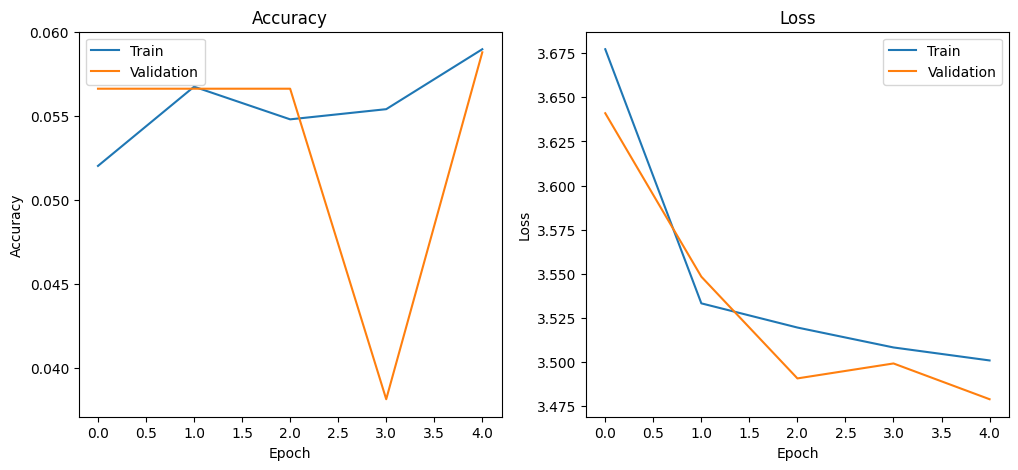

In [8]:
# ======================
# Accuracy vs Loss Graph
# ======================

plt.figure(figsize=(12,5))

# Accuracy
plt.subplot(1,2,1)
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(['Train','Validation'])

# Loss
plt.subplot(1,2,2)
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(['Train','Validation'])

plt.show()